`process_execute`
   Copies the command line into a page, allocates a `child_record` with
   `ref_cnt` set to 2, creates a thread, then waits on `loaded` for the child to
   report back. It adds the record to the list only if the child succeeds. 


   ...
   ... spawn a new kernel thread to run a user program while synchronising with
   that child until its executable binary finishes loading into memory. It
   first copies `cmd_line` into a freshly

`tid_t process_execute (const char *cmd_line)`
   Creates and starts a new process to run the user program specified from
   the input command-line string `cmd_line`, returning the tid of the thread 
   running the new process. 

   ... the manual's own description of `pagedir.c` says "you probably won't want
   to modify this code for this task, you may want to call some of its functions
   " ... 

   ... you will enable programs to interact with the OS via system calls. 

   You will be working out of the `userprog` directory ... ...

   ... all the test code from the last assignment ran as part of the kernel, 
   with full access to priviledged parts of the system. Once we start running
   user programs on top of the OS ... this is no longer true ... this
   task deals with the consequences

   we allow more than one process to run at a time. Each process has one thread
   (multi-threaded processes are not supported) ... must manage memory, 
   scheduling, and other state correctly to maintain this illustion
   > User programs are written under the illustion that they have the entire
   > machine. 

   In the previous task, we compiled our test code directly ... test your OS
   by running user programs ... must make sure that the user program interface
   meets the specifications described here, but given that constraint
   you are free to ... 

   CONSTRAINT: == make sure that the user program interface meets the
   specifications described here ... 


---


'process.ch'
   Basic user process support, including loading ELF binaries into memory.
   `process.h` defines `struct process`, which you are likely to modify in the
   last two weeks. 

pagedir.ch
   A simpler maanger for 80x86 hardware page tables

syscall.ch
   Whenever a user process wants to access some kernel functionality... it
   invokes a system call. This is a skeleton system call handler. Currently,
   it just prints a message and terminates the user process. 



   ...
```c
bool load (const char *file_name, void (**eip)(void), void **esp)
```

HOW `load()` WORKS IN PINTOS
   When a user process starts via `start_process ()`, ... it calls 

   - ... ALLOCATES A PAGE DIRECTORY ... calls `pagedir_create ()` to give the
     new user process its own isolated virtual address space ... 


        ```
        just know internally that start_process () itself is invoked whenever a new thread is scheduled after it's initial creationg from thread_create ()
        ```

```c
// A thread function that loads a user process and starts running it... 
start_process (void *args_)
    -> (process.c:287)
// to prepare the ELF executable for the CPU... 
load (args->cmd_line, &if_.eip, &if_.esp);   <--// if stands for interrupt frame
        -> (process.c:598) 
        // give new user process its own isolated virtual address space
        cur->pagedir = pagedir_create ();        
        
        -> (process.c:628-683)
        // Loads program segments... Loops through the program header table
        // `struct Elf32_Phdr phdr;` ... for each loadable segment
        switch (phdr.p_type)
          {
            ...
            case PT_LOAD:
              load_segment (...);       // line 675
            ...
          }

        -> (process.c:686)
        // SETS UP THE USER STACK. Calls `setup_stack ()` to allocate a zeroed
        // page at `PHYS_BASE` and sets the initial stack pointer (`*esp`)
        setup_stack (esp)

        -> (process.c:690)
        // SETS ENTRY POINT ... tells the CPU the exact memory address where
        // execution should begin when switching to user mode ... 
        *eip = (void (*) (void)) ehdr.e_entry;




```

-- LOADS PROGRAM SEGMENTS. Loop through the Program Header 

   ... you probably won't want to modify this code for this task, you may want
   to call some of its functions ... 

TASK 2 OVERVIEW, CITED
   1. User virtual memory runs from virtual `0x00000000` up to 
      virtual address `PHYS_BASE = 0xc0000000` ... Kernel virtual memory is 
      everything above it ... User memory is per process and kernel memory is 
      global ... 
   2. When the kernel switches process it switches page directory with 
      `pagedir_activate()` ... The base code already calls create, destry and
      activate for you ... 





   ... notably, `malloc ()` cannot be implemented because none of the 
   sys-calls (system calls) required for this task allows for memory allocation
   ... PintOS also can't run programs that use FP ops ... since the kernel
   doesn't save and restore the processor's FP unit when switching
   threads ... 

   ... until you copy a test program to the simulated file system, PintOS 
   will be unable to do useful work. You won't be able to do interesting things
   until yoyu copy a variety of programs to the file system. ... 

---
4.1.4 VIRTUAL MEMORY LAYOUT ... 
   ... virutal memory in PintoS is divided into two regions ... user virtual
   memory and kernel virtual memory ... 

   In Pintos, `pd` in `pagedir_activate (uint32_t *pd)`... stands for 
   PAGE DIRECTORY... a pointer to a 4KB array of 32-bit entries (directory 
   entries)... that maps a process' virtual address to physical memory frames .. 


How `pagedir_activate ()` works
   - PURPOSE. it makes `pd` the page table the CPU uses to translate addresses ... 

   ...
   ```
    Stores the physical address of the page directory into CR3 (or the PDBR
    = page directory base register) ... This activates the new page tables
    immediately ... 
   ```

```c

/* Sets up the CPU for running user code in the current thread.
   This function is called on every context switch. */
void
process_activate (void)
{
  struct process *cur = thread_current ()->process;
  
  /* Activate thread's page tables if running an active process. */
  if (cur != NULL)  
    pagedir_activate (cur->pagedir);            // <-- Points CPU's PDBR to thread_current ()->process->pagedir pointer!

  /* Set thread's kernel stack for use in processing
     interrupts. */
  tss_update ();
}

```




```c
static inline bool
is_user_vaddr (const void *vaddr)
   // Returns true for a user virtual address. It is named as one of the 
   // two functions for checking pointers ... 

void *
pagedir_get_page (uint32_t *pd, const void *uaddr)
   // Returns the kernel virtual address of the frame or a null pointer if 
   // unmapped... 
   // < -- RETURNS VIRTUAL ADDRESS IN KERNEL SPACE (above `PHYS_BASE`), not
   // a raw physical RAM address
      // see this -> 
      return pte_get_page (*pte) + pg_ofs (uaddr);
            /* Returns a pointer to the page that page table entry PTE points
               to. */
            static inline void *pte_get_page (uint32_t pte) {
               return ptov (pte & PTE_ADDR);
            }
                  // look at the definition of ptov and PTE_ADDR which is just 0xfffff000

```

WHY THE KERNEL NEEDS IT
   The kernel reads and writes memory that a user program points to. A user
   pointer is just a number chosen by the program... can be NULL, a kernel
   address such as virtual `0xc0000000` ... or a virtual page with no frame
   behind it... 
   
   If the kernel uses an unmapped virtual page ... a page fault happens in
   kernel mode and PintOS panics ... 

   A virtual page is "mapped" when the process's hardware page 

---
      A virtual page is "mapped" when the process's hardware page table has a valid entry linking that virtual address to an actual frame of physical RAM, with its "present" bit set to 1. When any code tries to read or write an unmapped virtual address, the CPU's memory management unit cannot find a physical RAM location and immediately triggers a hardware page fault exception.


---
      Your guess is right on the money: PintOS operates on the strict assumption that kernel code is bug-free and only ever dereferences valid memory. Because of this guarantee, page_fault() in exception.c treats any fault triggered while executing in kernel mode (SEL_KCSEG) as a fatal OS bug and immediately calls PANIC() to crash the entire machine. Even worse, if the kernel crashes mid-syscall after acquiring a lock or allocating memory, it leaks those resources and leaves downstream kernel structures in a permanently broken or deadlocked state. By verifying that user pointers are mapped before the kernel touches them, you catch bad addresses early and cleanly terminate just the offending user process instead of letting it trick the kernel into panicking the whole OS.


---
      ```sh
      ❯ okay so should the mental model in e just be this is important later, and just stop letting the ptov bug me?

      Yes. Think of pagedir_get_page () as answering two questions:

      1. Is this virtual page mapped to a frame? The NULL check answers this, and safemem only uses this answer.
      2. If it is mapped, where can the kernel access the frame? ptov () gives this answer. Task 2 does not use it.
      ```

THREAD VS PROCESS
    the end goal is to cook pasta. but we have two things in parallel, chef A boils pasta, chef B preps the puree sauce

    so is the thread each chef? (worker?)

    whilst the process is the whole process from start (raw ingreidents)... all the way to the end ogal?

# In PintOS, 1 program == 1 process
    ## A program only becomes multiple processes if it explicitl uses the 
    ## `exec` system call to launch a completely separate and new program
    ## in its isolated memory space ... 

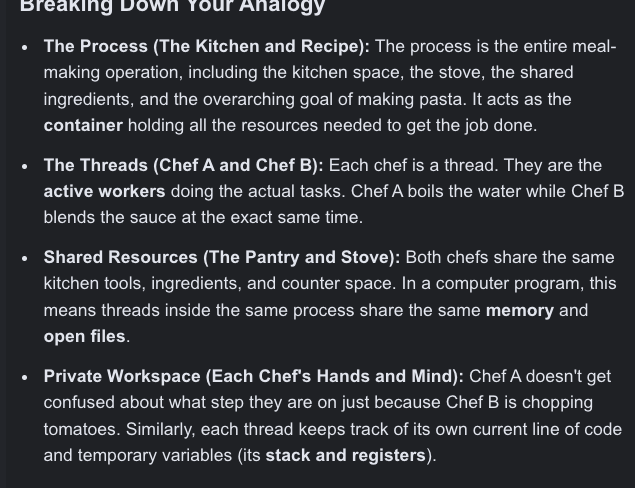

```c
lookup_page (uint32_t *pd, const void *vaddr, bool create)
   ...
   /*
   Returns the address of the page table entry for virtual address VADDR in 
   page directory PD...

   If PD does not have a page table for VADDR... .... create new table if 
   `bool create` is true, else just returns NULL ptr
   */


```

Time: 35 min
Topic: Argument passing
Manual (printed pp.): 4.3.3 (p33), 4.5.1 Program Startup (p40–41), 4.4.1 FAQ (p39)
Team code to read: process.c:270-390 (start_process tail, split_words, push, push_arguments), setup_stack at :821 (sm4925)
Grid rows it covers: Correct argument passing, no limits, abstraction, memory efficiency

```c
static inline bool
is_user_vaddr (const void *vaddr)
   // Returns true for a user virtual address. 
   return vaddr < PHYS_BASE;

void *
pagedir_get_page (uint32_t *pd, const void *uaddr)
   // Returns the kernel virtual address of the frame or a null pointer if 
   // unmapped... 



```

# TDL

   looks up the physical address that corresponds to user virtual address
   UADDR in PD. Returns the kernel virtual address corresponding to that
   physical address, or a null ptr if UADDR is mapped... 


   returns true for a user virtual address... it is named as one of the two
   functions for checking pointers... 

---

   writing `CR3` also flushes the TLB, so stale translations from the
   old process disappear ... 
   <-- PDBR = page directory base register ... 

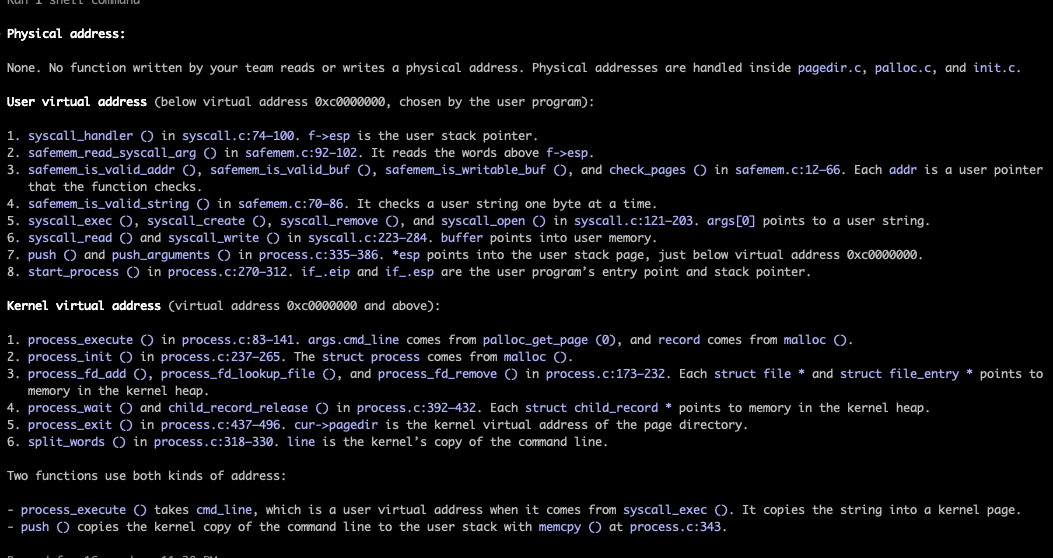

   The deciding question is WHOSE DATA IS IT... A user vaddr points to data
   that belongs to the user program, such as its stack, its buffers, and its
   strings ... The user chose that address and it may be invalid ... so 
   the KERNEL CHECKS IT BEFORE READING OR WRITING ON THE USER'S BEHALF ...
   A kernel vaddr points to data the kernel owns ... such as 
   `struct process`, `child_record`... the page directory and the copy of
   `cmd_line`... that memory comes from `palloc_get_page ()` or `malloc ()`

   ...

   and is the same in every process, so it stays valid across process
   switches ... 

i still have a gap in my understanding, that is 

* palloc_get_page () and malloc () always returns in kernel vaddr space
* kernel virtual address is just user vaddr but you add 0xc0000000
* kernel vaddr contains struct process and child_record
* if i allocate a space to write an integer of 700 at 0x0000000f, then it also exist in 0xc000000f... 


wait, in 4 sentences, why have the two of them together again? i get that 

* you need to keep all things in kernel inside the kernel... like important resources like struct process shouldn't be accessible b user program itself...
* but then why have them both linked, imo it will be a lot easier for my mind, if anything the user program needs, inside the OS, it was always just deal with in user vaddr; whilst kernel related things, where if cmd_line, struct process, or child_recod gets involved... then we always use kernel vaddr?

```
        Your proposed rule is exactly what PintOS already does: user things live at user addresses and kernel things live at kernel addresses. The two halves only share one 4 GB space so that during a system call the kernel can read the user’s buffer directly without swapping page directories (§4.1.4, p.29 [PDF 35]).
```

        this mean whenever in the list, that user virtual addresses are used, that we are just dealing with user related things? whilst if kernel vaddr is used, then we are just dealing with kernel related things? 

        but now then what about why does malloc and palloc_get_page only returns kernel vaddr? like how will these two functions ever be able to send things off to user? or is it that the user doesn't allocate memory from here at all, and does it somewhere else instead? and so whenever palloc_get_page is callled... its alway just the kernel

...
   Yes, your team uses method 1 ... `safemem_is_valid_addr ()` does both 
   checks in your notes ... `is_user_vaddr (addr) && pagedir_get_page ()`
   ... the kernel derefenrences the pointer only after it passes these
   checks ... such as at `syscall.c:88`

   ... no `get_user ()` or `put_user ()`, and exception.c is unchanged from
   the provided code ... 

---

   .... Method 1 is simpler and does not require changing `page_faul ()`...
   the trade off is a bit slower as now we need to do a pagetable_lookup 
   for every check ... 

4.1.5

   accesing user memory is a task tiself... we are implementing how the OS
   is accessing memory through pointers after all ...

HOW TO DO THIS
   1. verify validity of a user-provided pointer, then dereference it
      `pagedir_get_page ()`
      `is_user_vaddr ()`        <-- just check address < PHYS_BASE
   2. just check if poinjter below PHYS_BASE .... cause page fault ... and
      can handle by modifying the code for `page_fault`... faster as take
      advantages of the processor's MMU, so tend to be used in real kernels







```c

  if (!safemem_is_valid_bug (f->esp, sizeof syscall_num)) {
    process_exit (PROC_ERR);
  }

```

   `check_pages ()` answers one question ... is every byte of this user buffer
   on a mapped user page (`addr to addr + size - 1`)... and is that page 
   writable when the kernel needs to write?

   It checks one address per page instead of every byte... because 
   memory is mapped a whole page at a time ... so if one byte of a page is 
   mapped, then every byte in it is. It sounds `addr` down to its page 
   start with `pg_round_down ()`... It then steps 4096 bytes at a time until
   it passes the last byte ... Each page goes through 

   `safemem_is_valid_addr ()`... which is ... not `NULL`, then  
   `is_user_vaddr ()`... then `pagedir_get_page ()`... the two early
   exits cover edge cases... `size == 0` touches nothing so it passes... 
   `last < first` means `addr + size` wrapped past virtual `0xffffffff`, so it
   fails ... 

---

   ... `safemem_is_valid_buf ()` passes `writable = false` for user vaddr 
   memory the kernel only READS ... your `syscall_write ()` uses it for 
   `buffer` ... `safemem_read_syscall_arg ()` also uses it to check each
   4-byte argument above `f->esp` ... 

```c
static uint32_t
syscall_write (const uint32_t *args) {
   ...
   const void *buffer = (const void *) args[1];
   unsigned size = (unsigned) args[2];
   ...

   if (!safemem_is_valid_buf (buffer, size)) {
      process_exit (PROC_ERR);
   }
}
```

   ... `safemem_is_writable_buf ()` passes `writable = true` for memory
   the kernel WRITES INTO ... which is `buffer` in `syscall_read ()`... this
   extra check matters because pages can be mapped READ-ONLY ... without it a
   MALICIOUS `read (fd, main, 100)` could make the kernel overwrite the 
   program's OWN READ=-ONLY CODE instead of killing the process ... 
   `pagedir_is_writable ()` itself is not in the manual, 

   order matters... the CHECK `*str != '\0'` happens right after `str++` ... 
   and before the `while` condition reads `*str`. So the kernel never reads a
   byte on an unchecked page... 

---

   pg_ofs (str) == 0 is true only when str sits on the first byte of a new page. That is the only moment the string can step onto a page that hasn’t been checked yet. pg_ofs() returns the low 12 bits of the address (§A.7, p.72 [PDF 78]), so it is 0 exactly at a page boundary.
   


   ... the page allocator divides the memory it allocates into two pools ...
   by default each pool gets half of system memory above 1 MB ... 
   but the division can be chaned with the `-ul` kernel command line ...







   The page allocator (PALLOC) divides the mmeory it allocates into two
   pools ... called the KERNEL and the uSER pools...
   by defaul, each pool gets half of system memory above 1 MB ... 
    ... but division can be chaned...
   
   An allocation request draws from one pool or the other ...
   If one pool becomes empty, the other may still have free pages. The user 
   pool should be used for allocating memory for user processes and the kernel 
   pool for all other allocations ... This will only become important starting
   ... 

`void * palloc_get_page (enum palloc_flags flags)`
`void * palloc_get_multiple (enum palloc_flags flags, size_t page_cnt)`
   Obtains and returns one page, or `page_cnt` contiguous pages, respectively
   ... Returns a `NULLPTR` if pages cannot be allocated.

   The flags argument may be any combination of the following flags:

   `PAL_ASSERT`         [Page Allocator Flag]
      If the pages cannot be allocated, panic the kernel. This is only 
      appropriate during kernel initialisation. User processes should never
      be permitted to panic the kernel
   `PAL_ZERO`           [Page Allocator Flag]
      Zero all the bytes in the allocated pages before returning them. If not
      set, the contents of the newly allocated pages are unpredictable ...
   `PAL_USER`           [Page Allocator Flag]
      Obtain the pages from userpool ... if not set, pages are allocated from
      the kernel pool ... 

---

`void palloc_free_page (void *page)`
`void palloc_free_multiple (void *pages, size_t page_cnt)`
   Frees one page, or `page_cnt` contiguous pages ... respectively starting at
   `PAGES` ... All of the pages must have been obtained using 
   `palloc_get_page ()` or `palloc_get_multiple ()` ... 

`void * malloc (size_t size)`
   Obtains and returns a new block, from the kernel pool, at least size bytes
   long ... Returns a null pointer if size is zero or if memory is not available
   

# 4.3.2 Process Termination Messages
   Whenever a user process terminates, because it called `exit` or for any other
   reason, print the process's name and exit code, formatted as if 
   `printf( ...)` ... The name printed should be the name passed to 
   `process_execute ()`, omitting command-line arguments. Do not print messages
   when a kernel thread that is not a user process terminates, or when `halt`
   system call is invoked... The message is optional when a process fails to 
   load ... 

---

   `process_exit ()` tears down one user process and then ends its thread. 
   It releases the children's records and destroys the page directory, which
   frees ever user frame ... It then closes all files and the executables,
   frees `struct process`, and only at teh end reports `exit_code` to the parent
   and wakes it ... 

   `process_exit ()` runs when a USER PROCESS is done, whether it called
   `exit` or got killed by `safemem` with `PROC_ERR`. A plain kernel thread 
   never comes here... since it calls `thread_exit ()` directly and the 
   `cur != NULL guard covers any thread without a process.
   
   - tears down user process
    * releases children records
    * destroys page directory (freeing user fraem)
    * closes all files and executables
    * frees `struct process`
   - ends its thread
   

```c
tid_t
process_execute (const char *cmd_line) {
  struct process_args args;
  struct child_record *record;

  ...

  record = malloc (sizeof *record);

  if (args.cmd_line != NULL && record != NULL) {
    args.record = record;
    
  }

}
```

-- a question, can i know who runs process_init (), and process_execute(), 
   would it be the parent process which runs these for the child, which then
   creates a new thread for the child at the same time?

   or is this more so the case that the child thread runs itself? but this doesn't make sense... 

```c
struct child_record
  {
    tid_t tid;                /* Thread identifier of the child. */
    int exit_code;            /* Set by the child when it exits. */
    struct semaphore exited;  /* Upped by the child when it exits. */
    struct lock lock;         /* Protects ref_cnt. */
    // MAX 2, MIN 0
    int ref_cnt;              /* How many of parent and child still hold it. */
    struct list_elem elem;    /* Element in the parent's children list. */
  };

/* Passed from process_execute() to start_process().  It lives on the
   parent's stack, which is safe because the parent waits until the child
   has loaded. */
struct process_args
  {
    char *cmd_line;               /* Copy of CMD_LINE, split into words. */
    size_t cmd_line_size;         /* Its size, including the final null. */
    struct child_record *record;  /* Where the new process reports its exit. */
    struct semaphore loaded;      /* Upped by the child once it has loaded. */
    bool load_success;            /* Whether the child loaded. */
  };

/* An open file in a process's file descriptor table. */
struct file_entry
  {
    int fd;                   /* File descriptor the process uses. */
    struct file *file;        /* The open file. */
    struct hash_elem elem;    /* Element in the process's fd_table. */
  };
```

   ... a `child_record` exists only so a chlild process (program) can hand its
   exit code back to the parent, even after the child itself is gone. The
   parent cares because it often has to wait for one job to finish before 
   starting the next. 
   
   Take a shell as program 1: 
   - it calls `exec ("ls")`
   - and then `wait (ls_pid)`
   so it prints its next prompt only after ls has finished, the exit code
   tells it how `ls` ended, with 0 for success and -1 if the kernel killed it.

   If program 1 runs both `ls` and `grep` then each child gets its own record,
   so the parent can wait for them in any order. The manual defines this 
   contract under the `exec` and `wait` system calls ... 

   in PintOS a user program can't touch hardware, files or other processes 
   directly, so system calls are its only way to reach the OS. Task 2 has 13
   of them ... `halt`, ... `close`... Library functions are built on top of 
   them. For example, `printf()` in a user program ends up calling `write` on
   fd1. 

# printf.c
```c
#include <stdio.h>
#include <syscall.h>

int main (void) {
    pid_t pid = exec ("echo hi");
    int code = wait (pid);
    printf ("echo exited with %d\n", code)'
    return 0;
}
```

```output
hi
echo: exit(0)
echo exited with 0
printf: exit 0
```

   Yes to both.

   ONE WAY. (mainly children process to parent process)
   - The only real message is child writing `exit_code` and calling
     `sema_up (&exited)` for the parent to read . 
   Parent writes child record
   - The parent does write `record->tid` and `record->ref_cnt = 2`


   THE LIST.
   - The paren'ts `children` list (`&thread_current ()->process->children`)
     holds one `child_record` per child it started successfully and hasn't waited
     for yet ... 

```c
process_execute (const char *cmd_line);
// -> (process.c:112)
tid = thread_create (args.cmd_line, PRI_DEFALT, start_process, &args)



```










// what happens when start_process in 
    `tid = thread_create (args.cmd_line, PRI_DEFALT, start_process, &args)`
// runs
```c
/* As in task 1, new process (e.g. ls, or ./rucha.sh) is now a new thread
   which will run `START_PROCESS` as soon as it's started after reaching it
   with ROUND_ROBIN, BSD or immediate yielding if it's priority exceeds

   new process is added to `all_list` in thread_init ()

   `kernel_thread` immediately runs `START_PROCESS`... after stack has been
   switched over with THREAD_SCHEDULE_TAIL () -> PROCESS_ACTIVATE ()
*/
// -> (SCHEDULER)
schedule ()
    // -> thread.c
    switch_threads ()
    // -> thread.c
    thread_schedule_tail ()
        // -> thread.c:738
        process_activate ()
            // -> process.c:506 | does nothing for first time, else load PDBR
                // READ BLOCK BELOW
            pagedir_activate (cur->pagedir);    
            tss_update();           // points CPU ESP to cur->esp?
// -> (eip)
kernel_thread ()

// -> (thread.c:597)
function (); // which calls start_process ();
    // -> dereference function pointer
    start_process ();
        struct thread *cur = thread_current ();
        struct process_args *args = args;
        struct intr_frame if_;
        bool success;

        // -> process.c:278 // Initialise process
        success = process_init (cur, args->record);

        if success {
            // -> (process.c:270 and process.c:287-288)
            success = load (...) && push_arguments (...);
                // -> load (...)
                    // By then, the process and its new page directory exist, so this 
                    // call loads CR3.
                process_activate ();  
        }

        /* Tell the parent whether the load worked.  ARGS is on the parent's
        stack and the parent carries on as soon as it wakes, so this is the
        last use of it. */
        args->load_success = success;
        sema_up (&args->loaded); // upped by child once it has loaded

        asm volatile ("movl %0, %%esp; jmp intr_exit" : : "g" (&if_) : "memory");

        
        `JUMPS TO _start(), which calls main() entry point`
        `the user program runs until it makes a system call or gets killed`
```

`asm volatile ("movl %0, %%esp; jmp intr_exit" : : "g" (&if_) : "memory");`
   This line is the jump from the kernel into the user program for the very 
   first time. The x86 only enters user mode through an `iret` (return from
   interrupt)... so the kernel fakes an interrupt that never happened...
   It points `esp` at `if_`which was filled in earlier 
   ```c
      memset (&if_, 0, sizeof if_);
      if_.gs = if_.fs = if_.es = if_.ds = if_.ss = SEL_UDSEG;
      if_.cs = SEL_UCSEG;
      if_.eflags = FLAG_IF | FLAG_MBS;
      success = load (args->cmd_line, &if_.eip, &if_.esp) && 
                push_arguments (&if_.esp, args->cmd_line, args->cmd_line_size);
   ```
   with user segment selectors, `eip` set to the ELF entry point and `esp` set
   to the user stack that `push_arguments` built. ...  (basically uses
   the full built stack and buffer... )
   `intr_exit` then pops that frame and runs `iret`, so the CPU lands in
   user mode at `_start ()` and never comes back to this line ... 




        Yes. process_activate () runs twice for a new process, but each call does a different job.

        The first call comes from thread_schedule_tail (). At that point, the thread does not have a process yet: process_init () has not run, and t->process is still NULL from thread.c:665. So the test at process.c:506 fails, and pagedir_activate () is skipped. Only tss_update () runs.

        The second call comes from load (). By then, the process and its new page directory exist, so this call loads CR3.

        Two parts of your trace need fixing. tss_update () does not change the CPU’s esp. It sets tss->esp0 to the top of the thread’s kernel page, for the next time the CPU enters from user mode. switch_threads () switches the stack itself, and thread_schedule_tail () runs only after that switch.

```c
static bool
push_arguments (void **esp, const char *line, size_t size) {
  ...

  // this pushes the whole `ls'\0'-a'\0'hi`
  // because it pushes using SIZE == record->cmd_line_size;
  if (!push (esp, line, size)) {...} 
  
  /* Align the stack, then push argv[argc] and the pointers to the words,
     last word first, so that `argv[0]` is at the lowest address
  */
  // 4 bytes alignment      / data alignment // word alignment
  *esp = (void *) ROUND_DOWN ((uintptr_t) *esp, sizeof (uint32_t)); 
  if (!push (esp, &null, sizeof null)) { ... }

  for (word = first + size - 1; word >= first )

  /*
      Before alignment (after process.c:359):
        virtual 0xc0000000  +----------------+  PHYS_BASE
        virtual 0xbffffffc  | "bar\0"        |
        virtual 0xbffffff8  | "foo\0"        |
        virtual 0xbffffff5  | "-l\0"         |
        virtual 0xbfffffed  | "/bin/ls\0"    |  <- esp (not a multiple of 4)

      After alignment and the remaining pushes (after process.c:385):
        virtual 0xc0000000  +----------------+  PHYS_BASE
        virtual 0xbffffffc  | "bar\0"        |
        virtual 0xbffffff8  | "foo\0"        |
        virtual 0xbffffff5  | "-l\0"         |
        virtual 0xbfffffed  | "/bin/ls\0"    |
        virtual 0xbfffffec  | 1 unused byte  |  <- esp after ROUND_DOWN (line 367)
        virtual 0xbfffffe8  | argv[4] = NULL |  line 368
        virtual 0xbfffffe4  | argv[3] = virtual 0xbffffffc |
        virtual 0xbfffffe0  | argv[2] = virtual 0xbffffff8 |
        virtual 0xbfffffdc  | argv[1] = virtual 0xbffffff5 |
        virtual 0xbfffffd8  | argv[0] = virtual 0xbfffffed |  lines 372-382
        virtual 0xbfffffd4  | argv    = virtual 0xbfffffd8 |  line 384
        virtual 0xbfffffd0  | argc    = 4    |  line 384
        virtual 0xbfffffcc  | return  = NULL |  <- esp, line 385
  */
}


```

```c
// line 103 -- tid_t process_execute (const char *cmd_line)
      args.cmd_line_size = split_words (args.cmd_line);
      
// line 287 -- static void start_process (void *args_)
      success = load (args->cmd_line, &if_.eip, &if_.esp) && 
                push_arguments (&if_.esp, args->cmd_line, args->cmd_line_size);

```
-- 103 = The parent cals `split_words` on its `args.cmd_line` copy and saves
         the result in `args.cmd_line_size`
-- 287 = The child passes `args->cmd_line` to `load`. `load` stops at the first
         null byte, so it sees only `ls` ... then it passes `args->cmd_line`
         and `args->cmd_line_size` to `push_arguments ();`


   `load ()` ... NO. only need to know three things it does:
   1. It creates the page directory
   2. It maps the code, data and stack pages
   3. It keeps the executable open with `file_deny_write ()`

   The last part is your team'ss change at lines 686 to 696

```c  
void
process_activate (void) {
  if (cur != NULL) {
    pagedir_activate (cur -> pagedir);      // loads PD into PDBR-CR3
  }

  tss_update ();   // <-- sets ESP to point at current thread's kernel stack
  /*
           4 kB +---------------------------------+
                |          kernel stack           |
                |                |                |
                |                |                |
                |                V                |
                |         grows downward          |
                |                                 |
                |                                 |
                |                                 |
                |                                 |
                |                                 |
                |                                 |
                |                                 |
                |                                 |
                +---------------------------------+
                |              magic              |
                |                :                |
                |                :                |
                |               name              |
                |              status             |
           0 kB +---------------------------------+
  */
}

be obsessed with SEMAPHORES and RACE CONDITIONS in `process.c`
similarly too, for hashes in `process.c`



```c







process_execute (const char *cmd_line) {
  struct process_args args;
  struct child_record *record;

  sema_init (&args.loaded, 0);
  sema_init (&record->exited, 0);
  lock_init (&record->lock);
  
  LOAD ATTEMPT
  tid = thread_create (args.cmd_line, PRI_DEFAULT, start_process, &args);

  if (tid == success)
    sema_down (&args.loaded);
      // can't move yet, can only start executing palloc_free_page and
      // list_push_back after start_process () runs sema_up (&args.loaded)
}
      /*CHILD PROCESS FINISHED INITIALISATION*/

static void 
start_process (void *args_) {
  process_init (); <-- fill up current_thread ()->process;
  load () && push_arguments () <-- filling up ESP stack with program argc, argv
  sema_up ();
}
      
      /*CHILD PROCESS FINISHED INITIALISATION*/





int
process_wait (tid_t child_tid)
{
  for () {
    /* SELECTED CORRECT CHILD PROCESS */
    
    sema_down (&child->exited);
    /*CHILD PROCESS EXITED BY NOW*/
  }
}


void 
process_exit () {
  while (!list_empty (&cur->children))
  {
    child_record_release (list_entry (
      list_pop_front (&cur->children), 
      struct child_record,
      elem
    ))
  }

  /* destroying thread_current -> pagedir PAGE DIRECTORY */

  // close all open files and FD table
  // close executale file?
  // destroy current process' struct    thread_current ()->process = NULL;

  if (record != NULL) {
    printf (exited)
    record->exit_code = exit_code;    <-- tells parents about it... 
    sema_up (&record->exited);
    /*CHILD PROCESS ALREADY FULLY EXITED BY NOW*/

    child_record_release (record);
        <- child process already destroyed, but child record perseveres...
    /*DESTROYS THE RECORD IF PARENT CHILD NO LONGER RUNNING*/
  }
}
```


   Suppose the parent has already exited, leaving `ref_cnt` at 1. If the child
   released its hold first, the count would drop to 0, and the record would be 
   freed at `process.c:430` (`child_record_release (struct child_record *record)`)


---

/*
  lock to avoid both parent and child writing it at once, resulting in ref_cnt
  incorrectly == 1... when it should be == 0. this will lead to child_record
  never being free, and memory leak
*/

```c
static void
child_record_release (struct child_record *record)
{
  bool last;

  lock_acquire (&record->lock);
  last = --record->ref_cnt == 0;
  lock_release (&record->lock);

  if (last)
    {
      free (record);
    }
}
```


   ... `child_record` is your team's own design .. since the manual 

```c
struct process_args;

tid_t
process_execute (const char *cmd_line) {
  struct child_record *record;
  // release if attempt to load chilld process failed
  child_record_release (record);
}

int
process_wait (tid_t child_tid) {
  struct list *children = &thread_current ()->process->children;
  struct list_elem *e;
  
  for (e = list_begin (children); e != list_end (children); e = list_next (e)) {
    struct child_record *child = list_entry (e, stuct child_record, elem)
    ...

    if (child->tid != child_tid) {
      continue;
    }
    sema_down (&child->exited);
    child_record_release (child);
      // only release after selected child process already exited, then would've 
      // been freed here... 
    return exit_code;
  }
  return PROC_ERR;
}

// only release child record here if ran out of memory for allocating struct 
// process
static bool
process_init (struct thread *t, struct child_record *record) {
  child_record_release (record);  
}

// here we are merely just decrementing ref_cnt
static void
child_record_release (struct child_record *record) {
  lock_acquire (&record->lock);
  last = --record->ref_cnt == 0;
  lock_release (&record->lock);
  ...
}

void
process_exit (int exit_code) {
  if (cur != NULL) {
    struct child_record *record = cur->record;

    // child process decrements all of it's grandchildren
    while (!list_empty (&cur->children)) {
      child_record_release (list_entry (list_pop_front (...)))
    }

    if (record != NULL) {
      // child process decrements itself 
      child_record_release (record);
    }
  }
}
```






```c
static size_t
split_words (char *line)
{
  char *p;

  for (p = line; *p != '\0'; p++)
    {
      if (*p == ' ')
        {
          *p = '\0';
        }
    }
  return p - line + 1;
}
```

-- The progream reads each `argv[i]` as a separate C string, so each word must
   end witha  null byte, not a space. Replacing spaces with null bytes does this
   without copying each word, so push_arguments can copy the whole line once
   with `memcpy` and point the `argv` entries into it... It also makes
   `load (program, ...)` and `strlcpy` for the thread name see only the 
   program name, because both stop at the first null byte. The function returns
   thefull `size` because `strlen` wouldstop at the first null byte and miss the 
   other words... 

   `ref_cnt` stands for REFERENCE COUNT. It counts how many owners still hold
   the `child_record`: it starts at 2 fo the parent and the child, and each
   `child_record_release ()` takes one away. Whoever brings it to 0 frees the
   record ...

   ever path in this file that ends a process goes through 
   `process_exit (exit_code)` ... and that sets `exit_code` before `sema_up ()`
   ... The one place left to check ... 

   ... manual only describes how `wait` must behave ... and never names a 
   struct for it. 
   
-- The parent points to it through its `children` list 
   
   from the
   moment `process_execute ()` pushes it after a successful load until 
   `process_wait ()` or `process_exit ()` releases it... 
   
   
-- The child points to
   it through `process->record` from the moment `process_init ()`

```c
process_exit ()
process_execute ()
process_wait ()
process_write ()
```

- 1:00 pm back
- 2:00 pm [fully understand process.ch]
                understand what's up with the hashings
                file descriptor
                skim syscall.c
- 2:15 pm - 3:45 pm [grinding answers to potential questions]
- 3:45 pm depart

   - (§4.5.2, p.41 [PDF 47])
   - PAGE 32
      4.2 Suggested Order of Implementation

      till PAGE 42, THEN DONE!


- question 1: can i know how does pagedir_is_writable work, in 4 sentences...
  so it seems it just takes in the current page at every 4096 incremetns....

  ... im also confused about the edge case whre it seems if:

  case !writable:
     then if !pagedir_is_writable (...) returns FALSE, and writable is also 
     FALSE... then wouldn't this lead to reutnr FALSE?? wouldn't this be bad?
     
     as i would think that jusst because something is writable, doesn't mean 
     it's invalid? 

HOW `pagedir_is_writable ()` WORKS
   It's in `pagedir.c:219-224`...

```c
bool            // vpage == virtual page
pagedir_is_writable (uint32_t *pd, const void *vpage) {
    uint32 *pte = lookup_page (pd, vpage, false);
    return pte != NULL && (*pte & PTE_W) != 0;
}


(*pte & PTE_W) != 0
```

   ... some pages in user addr are READ-ONLY ... this is why `syscall_read ()`
   uses `safemem_is_writable_buf ()` and `syscall_write ()` uses
   `safemem_is_valid_buf ()` ... 

- `read (fd, buffer, size)` reads from the FILE `fd` and the kernel WRITES into
  `buffer` ... so it needs `safemem_is_writable_buf ()`

- `write (fd, buffer, size)` writes to the FILE `fd` and the kernel READS
  from `BUFFER`... so `safemem_is_valid_buf ()` is enough ... 

```c
/* Round up to nearest page boundary. */
static inline void *pg_round_up (const void *va) {
  return (void *) (((uintptr_t) va + PGSIZE - 1) & ~PGMASK);
}
```

```c
/* Returns true if the PTE for virtual page VPAGE in PD is writable.
   Returns false if PD contains no PTE for VPAGE. */
bool
pagedir_is_writable (uint32_t *pd, const void *vpage) 
{
  uint32_t *pte = lookup_page (pd, vpage, false);
  return pte != NULL && (*pte & PTE_W) != 0;
}
```

-- `check_pages ()` is only used for user virtual addresses.... It is a 
   static function in `safemem.c`... Its two callers are 
   `safemem_is_valid_buf ()` ... and `safemem_is_writable_buf ()`

   They only get pointers from the user program: `f->esp`, syscall arguments,
   and the `read` and `write` buffers ... A kernel virtual address would fail
   the `is_user_vaddr ()` check ... the kernel trusts its own pointers, so it 
   does not check them ... 

-- Pages are scattered in physical memory, but not in virtual memory. Virtual
   pages are next to each other, so the page after virtual address ... is#
   always ... The physical frames behind them can be anywhere ... 
   `check_pages ()` walks virtual addresses, so adding 4096 bytes always reaches
   the next page... 

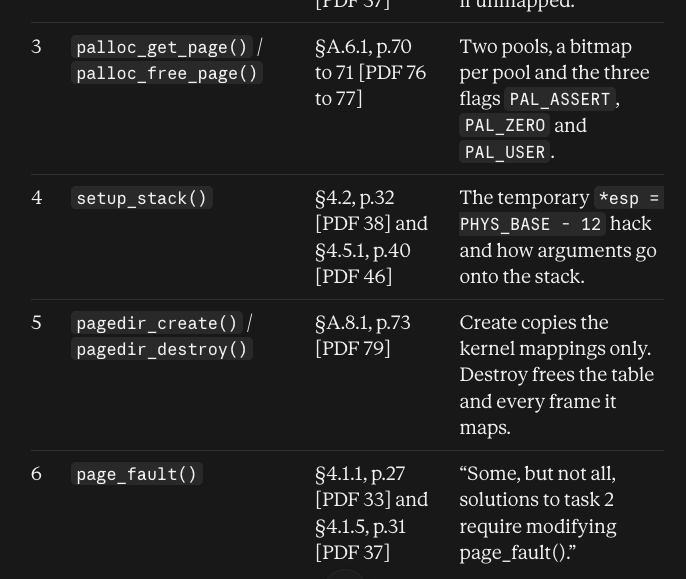

```sh
#: 1
Time: 35 min
Topic: Argument passing
Manual (printed pp.): 4.3.3 (p33), 4.5.1 Program Startup (p40–41), 4.4.1 FAQ (p39)
Team code to read: process.c:270-390 (start_process tail, split_words, push, push_arguments), setup_stack at :821 (sm4925)
Grid rows it covers: Correct argument passing, no limits, abstraction, memory efficiency
────────────────────────────────────────
#: 2
Time: 40 min
Topic: Syscall entry and safe user memory
Manual (printed pp.): 4.5.2 System Call Details (p41), 4.1.5 Accessing User Memory (p30–32), A.7 Virtual Addresses (p72), A.8.2 Inspection (p74)
Team code to read: syscall.c:1-103 (dispatch table, handler), all of safemem.c (syl25, st3125)
Grid rows it covers: Abstracted handler, abstracted memory checks
────────────────────────────────────────
#: 3
Time: 50 min
Topic: exec / wait / exit lifecycle
Manual (printed pp.): 4.3.2 Termination Messages (p33), exec/wait/exit in 4.3.4 (p34–35), A.3 Processes (p61–62), A.4.2–A.4.3 Semaphores and
  Locks (p63–64)
Team code to read: process.h, process.c:1-143 (child_record, process_execute), :237-269 process_init, :392-500 wait, release, exit (sm4925,
  st3125)
Grid rows it covers: Encapsulation, wait/exit races, no global sync, memory leaks (2 marks), efficient storage, child load success
────────────────────────────────────────
#: 4
Time: 35 min
Topic: fd table and file syscalls
Manual (printed pp.): Rest of 4.3.4 (p35–37), 4.3.5 Denying Writes (p37), 4.4.2 FAQ (p39–40), A.10.1–A.10.5 Hash Table (p82–87)
Team code to read: process.c:145-236 fd helpers (syl25), syscall.c:145-322 (your code, so skim), file_deny_write at process.c:611
Grid rows it covers: Thread-safe fd storage, processes and filesystem kept separate
────────────────────────────────────────
#: 5
Time: 20 min
Topic: Self-test
Manual (printed pp.): Marking grid parts 1–3
Team code to read: Your answers
Grid rows it covers: All
```

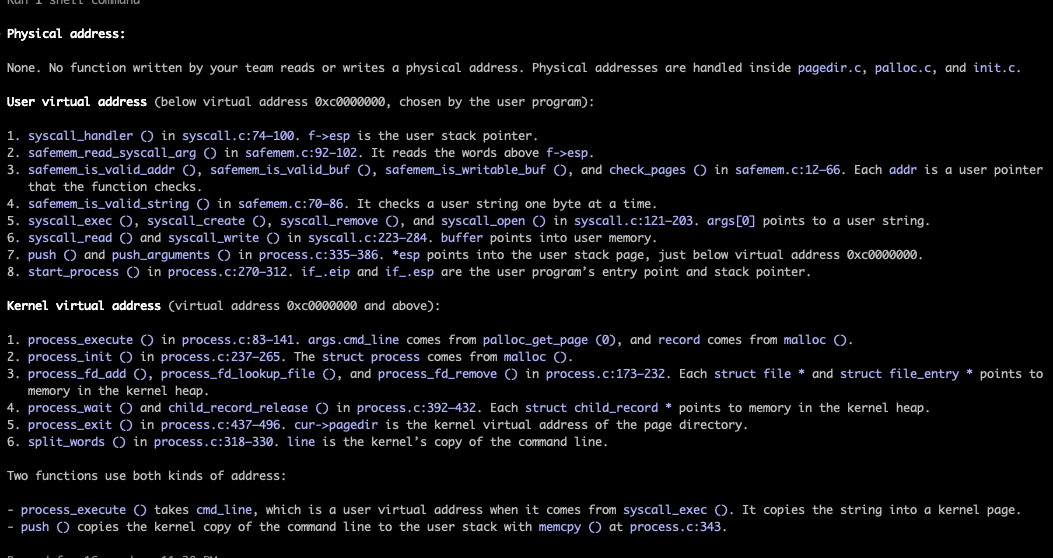

-- PAGE DIRECTORY -> PAGE TABLE -> PHYSICAL PAGE (Frame)


-- PAGE DIRECTORY -> PAGE TABLE -> PHYSICAL PAGE (Frame)




-- An ELF (Executable and Linkable Format) is the standard binary file format
   used for executables, object code, shared libraries, and core dumps on 
   Linux and Unix-like operating systems... 

   - RUNS PROGRAMS
   - STORES CODE AND DATA
   - SUPPORTS LIBRARIES .... 

-- `strspn (const char *string, const char *skip)`
   RETURNS the index of the first char in STRING which character isn't inside 
   SKIP

-- `strchr (skip, c)` asks whether `c` is in the set. `NULL` means it is not, 
   <-- basically, it just checks whether is `c` inside of `skip`. that's all...



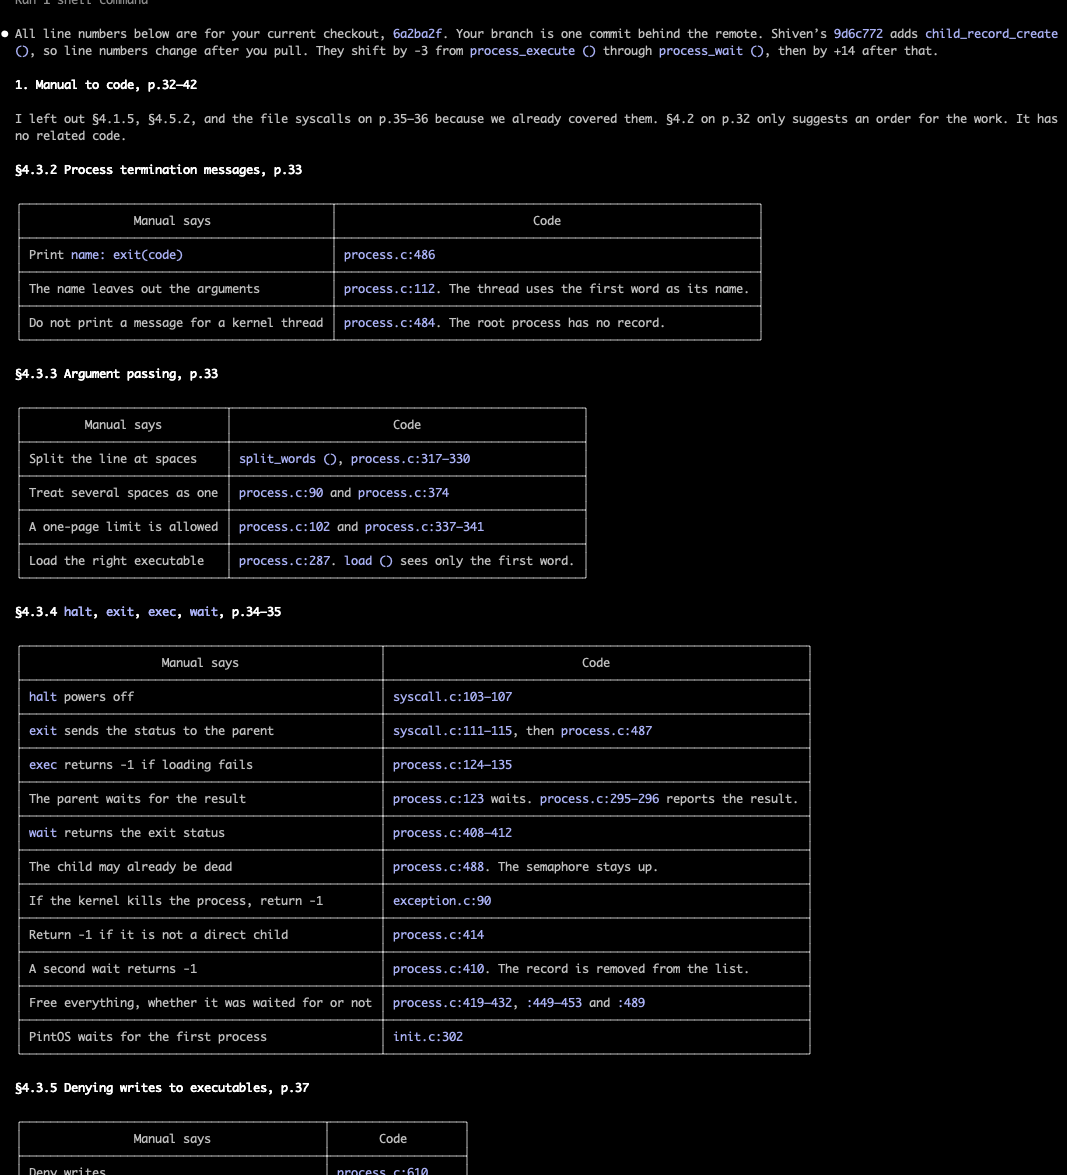

```c
// which bucket does this fd go in?
static unsigned
fd_entry_hash (const struct hash_elem *elem, void *aux UNUSED)


static bool
fd_entry_less (const struct hash_elem *a, const struct hash_elem *b,
               void *aux UNUSED)

static void
fd_entry_destroy (struct hash_elem *elem, void *aux UNUSED)

---
int
process_fd_add (struct file *file)

struct file *
process_fd_lookup_file (int fd)

struct file *
process_fd_remove (int fd)



```

syscall is called
INTERRUPTED
all registers and ESPs are pushed to `struct intr_frame *f`
`intr_frame` is then passed to `syscall_handler ()`

- 1:00 pm back
- 2:00 pm [fully understand process.ch]
                understand what's up with the hashings
                file descriptor
                skim syscall.c
- 2:15 pm - 3:45 pm [grinding answers to potential questions]
- 3:45 pm depart

   - (§4.5.2, p.41 [PDF 47])
   - PAGE 32
      4.2 Suggested Order of Implementation

      till PAGE 42, THEN DONE!


GOAL 1 TOMMOROW: Understand process.c
GOAL 2: reskim syscall.ch
GOAL 3: Attempt to understand what are choices made to avoid issues listed below
GOAL 4: Prepare to be questioned about dynamics below

- Lazy loading of `exec/mmap` pages
- Safe `hash_less` comparisons
- `SEL_KCSEG` page-faults still PANIC
- Locality of `mapid` and `mmap` table
- Efficient read-only sharing look-up
- Sharing implemented for `mmap` file pages
- Eviction fairness
- Obvious hash collisions avoided
- Synchronisation of frame eviction
- Sensible eviction algorithm
- Efficient mmap overlap check
- No superfluous locking
- Returns status of kernel function calls checked

1 mark - Processes fully encapsulated from threads
1 mark - Argument passing fully correct and no arbitrary limits
1 mark - Argument passing code is well abstracted
1 mark - Argument passing memory use is efficient 
1 mark - Avoids unnecessary synchronisation in reporting child load success
1 mark - System call handler code is well abstracted
1 mark - System call safe user-provided memory checks are well abstracted
1 mark - Processes, system calls and filesystem are fully encapsulated

1 mark - Thread-safe access to file descriptor storage and counters during system calls
1 mark - No race conditions in the wait system call
1 mark - No race conditions in the exit system call
1 mark - Avoids global data and synchronisation in `exec/wait/exit` system calls
2 mark - No memory leaks in parent / child termination
1 mark - Efficient storage of parent / child information

process.ch
safemem.ch
syscall.c

Meets Expectations
RED
- Function level code commenting
- Lazy loading of `exec/mmap` pages
- Safe `hash_less` comparisons
- `SEL_KCSEG` page-faults still PANIC
- Locality of `mapid` and `mmap` table


BLUE
- Efficient read-only sharing look-up
- Sharing implemented for `mmap` file pages
- Eviction fairness
- Git "conventional commit" style


BLACK
- Phase (paragraph) level code commenting
- Consistent Code Layout
- Function naming conventions
- Not efficient read-only sharing lookup
- Obvious hash collisions avoided
- Synchronisation of frame eviction
- Sensible eviction algorithm
- Efficient mmap overlap check
- No magic numbers
- No superfluous locking
- No additional performance issues
- No inefficient memory allocations
- Returns status of kernel function calls checked
- Git use and commit message quality



Task 2 Code Review Mark-sheet
   Correctness, Efficiency, and Design

1 mark - Processes fully encapsulated from threads
1 mark - Argument passing fully correct and no arbitrary limits
1 mark - Argument passing code is well abstracted
1 mark - Argument passing memory use is efficient 
1 mark - Avoids unnecessary synchronisation in reporting child load success
1 mark - System call handler code is well abstracted
1 mark - System call safe user-provided memory checks are well abstracted
1 mark - Processes, system calls and filesystem are fully encapsulated

1 mark - Thread-safe access to file descriptor storage and counters during system calls
1 mark - No race conditions in the wait system call
1 mark - No race conditions in the exit system call
1 mark - Avoids global data and synchronisation in `exec/wait/exit` system calls
2 mark - No memory leaks in parent / child termination
1 mark - Efficient storage of parent / child information